Linear Regression will use Species, culmen_length, culmen_depth, flipper_length, and sex to predict body mass.

** Since Species and Island overlap a lot, we will leave Island out of the Features list.


In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import root_mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

**LINEAR REGRESSION**

1. CLEANING DATA

In [2]:
#Load in the dataset
penguin_size = pd.read_csv('/content/penguins_size.csv')

#drop columns with NaN
penguin_size_cleaned = penguin_size.dropna()

#checking the distinct values
for col in penguin_size_cleaned.select_dtypes(include="object"):
    print(col, penguin_size_cleaned[col].value_counts(dropna=False), "\n")

species species
Adelie       146
Gentoo       120
Chinstrap     68
Name: count, dtype: int64 

island island
Biscoe       164
Dream        123
Torgersen     47
Name: count, dtype: int64 

sex sex
MALE      168
FEMALE    165
.           1
Name: count, dtype: int64 



In [3]:
#remove the invalid value for sex
penguin_size_cleaned = penguin_size_cleaned[penguin_size_cleaned["sex"].isin(["MALE", "FEMALE"])]

penguin_size_cleaned.head()

penguin_size_cleaned.to_csv('cleaned_penguin_size_data_regression.csv', index=False)

2. FEATURE PREPARATION AND SELECTION

a. One Hot Encoding

In [4]:
categorical_columns =   ["species", "sex"]
encoder = OneHotEncoder(sparse_output=False, drop = "first")
encoded_data = encoder.fit_transform(penguin_size_cleaned[categorical_columns])
encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(categorical_columns),
    index=penguin_size_cleaned.index,
)
encoded_penguin_size = pd.concat(
    [penguin_size_cleaned.drop(columns=categorical_columns), encoded_df],
    axis=1
)

print("\nOne-Hot Encoded Data:")
print(encoded_penguin_size)


One-Hot Encoded Data:
        island  culmen_length_mm  culmen_depth_mm  flipper_length_mm  \
0    Torgersen              39.1             18.7              181.0   
1    Torgersen              39.5             17.4              186.0   
2    Torgersen              40.3             18.0              195.0   
4    Torgersen              36.7             19.3              193.0   
5    Torgersen              39.3             20.6              190.0   
..         ...               ...              ...                ...   
338     Biscoe              47.2             13.7              214.0   
340     Biscoe              46.8             14.3              215.0   
341     Biscoe              50.4             15.7              222.0   
342     Biscoe              45.2             14.8              212.0   
343     Biscoe              49.9             16.1              213.0   

     body_mass_g  species_Chinstrap  species_Gentoo  sex_MALE  
0         3750.0                0.0             

b. Feature Selection

In [5]:
X = encoded_penguin_size[['culmen_length_mm','culmen_depth_mm','flipper_length_mm','species_Chinstrap','species_Gentoo','sex_MALE']]
y = encoded_penguin_size['body_mass_g']

c. Splitting data into training and testing

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Total number of data points:", len(X))
print(f"Training data points:", len(X_train))
print(f"Testing testing points:", len(X_test))

print("Training set sample:")
display(X_train.head())
print("Testing set sample:")
display(X_test.head())

Total number of data points: 333
Training data points: 233
Testing testing points: 100
Training set sample:


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,species_Chinstrap,species_Gentoo,sex_MALE
27,40.5,17.9,187.0,0.0,0.0,0.0
292,48.2,15.6,221.0,0.0,1.0,1.0
302,47.4,14.6,212.0,0.0,1.0,0.0
62,37.6,17.0,185.0,0.0,0.0,0.0
181,52.8,20.0,205.0,1.0,0.0,1.0


Testing set sample:


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,species_Chinstrap,species_Gentoo,sex_MALE
30,39.5,16.7,178.0,0.0,0.0,0.0
317,46.9,14.6,222.0,0.0,1.0,0.0
79,42.1,19.1,195.0,0.0,0.0,1.0
201,49.8,17.3,198.0,1.0,0.0,0.0
63,41.1,18.2,192.0,0.0,0.0,1.0


3. CREATING AND FITTING THE MODEL

In [9]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

LinearRegression()

In [18]:
# Get the intercept (beta_0)
print(f"Intercept: {lin_reg.intercept_:.4f}")

# Pair feature names with their coefficients (beta_1, beta_2, ...)
coef_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": lin_reg.coef_
}).sort_values(by="Coefficient", key=abs, ascending=False)

print(coef_df)

Intercept: -1509.6534
             Feature  Coefficient
4     species_Gentoo  1042.261718
5           sex_MALE   390.211176
3  species_Chinstrap  -201.056650
1    culmen_depth_mm    67.884763
2  flipper_length_mm    16.477989
0   culmen_length_mm    15.936956


4. MAKING PREDICTIONS

In [10]:
y_pred = lin_reg.predict(X_test)

5. RESULTS

In [19]:
#R squared score
r2 = r2_score(y_test, y_pred)
print(f"R-squared: {r2:.4f}")

#RMSE score
rmse = root_mean_squared_error(y_test, y_pred)
print(f"RMSE: {rmse:.4f}")

y_test_std = y_test.std()
print(f"Target's standard deviation: {y_test_std:.4f}")

R-squared: 0.8924
RMSE: 254.5153
Target's standard deviation: 779.8398


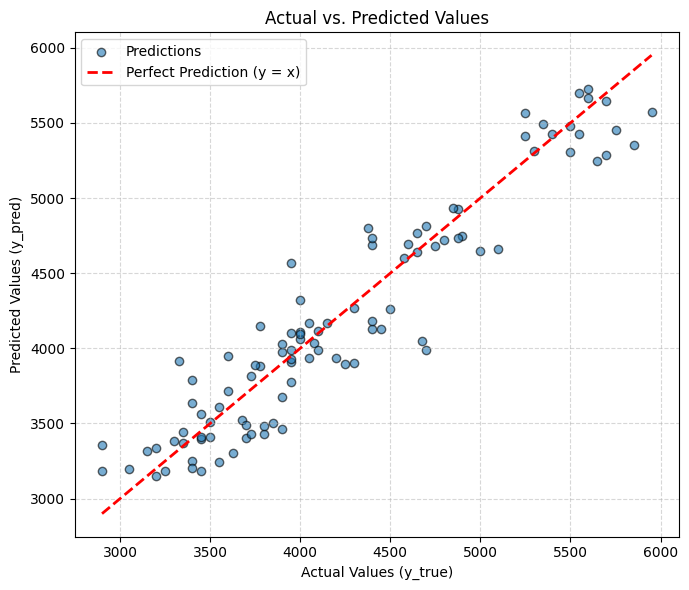

In [17]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.6, edgecolors="k", label="Predictions")

# Plot the 45-degree perfect prediction line (y = x)
min_val = min(np.min(y_test), np.min(y_pred))
max_val = max(np.max(y_test), np.max(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], "r--", lw=2, label="Perfect Prediction (y = x)")

plt.xlabel("Actual Values (y_true)")
plt.ylabel("Predicted Values (y_pred)")
plt.title("Actual vs. Predicted Values")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()



RESULT EXPLANATION:

1. Explain 2 coefficients
-  sex_MALE (coefficient 390.2): A male penguin is predicted to weigh 390 grams more than a female penguin, given they are the same species and have the same measurements.
- culmen_depth_mm (coefficient 67.9): For a 1 mm increase in culmen depth, predicted body mass increases by about 68 grams, holding species, sex, culmen length and flipper length fixed.

2. R squared Score = 0.8924
- The model explains 89% of the variability in penguin's body mass.

3. Root Mean Squared Error = 254.5
- The model's prediction is typically off by 254.5 grams.
- Compared with the target's standard deviation = 779.8, which is the error you'd get by always predicting the average mass. The model's error is about one-third of that baseline, so the features are capturing real structure in the data.
4. Prediction versus Actual Observation Plot
- The predicted vs. actual plot shows the test-set points clustered tightly around the y = x line, so the model's predictions generally match the true body masses, consistent with R² = 0.89. The spread is fairly even across the range, with no systematic over- or under-prediction. The model slightly overestimates the lightest penguins and underestimates the heaviest, and a few penguins are off by 500–700 g. These larger misses account for most of the RMSE of about 250 g.